## Preprocessing - Oligo and Polymetastatic Patients Clinical Data ##

This notebook focuses on clinical data preprocessing for the oligometastatic and polymetastatic breast cancer dataset.

## Inputs ##

- `/mnt/data3/MCPP-Breast/Clinical-Data/20260406-mcpp-breast-clinical-data.csv`: clinical data for the full breast cancer cohort

## Outputs ##

- `20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing.csv`  
  Exported version of the final preprocessed dataframe after:
  - feature engineering;
  - removal of high-null, post-primary, metastatic-only, progression-related, and low-quality variables;
  - one-hot encoding;
  - grouping of selected encoded variables;
  - removal of highly correlated features.

- `mcpp-breast-clinical-all-metastatic-data-preprocess-artifacts.pkl`  
  Saved preprocessing artifacts used to ensure the same transformations can be applied to future datasets, including:
  - fitted encoding pipeline;
  - numerical columns;
  - columns kept outside the encoding pipeline;
  - cleaned dataframe template;
  - processed feature template;
  - grouped feature definitions;
  - final list of correlated columns removed.

## Import Libraries and Load Data ##

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

import os
import sys
import pandas as pd

path_directory = '/mnt/data3/MCPP-Breast/Clinical-Data/'
file_path = os.path.join(path_directory, '20260406-mcpp-breast-clinical-data.csv')

thesis_print(file_path)
thesis_print(os.path.exists(file_path))

df_clinical = pd.read_csv(file_path, sep=';')
thesis_print(df_clinical.shape)

/mnt/data3/MCPP-Breast/Clinical-Data/20260406-mcpp-breast-clinical-data.csv
True
(217, 1440)


In [2]:
# Standard Libraries
import re
import joblib

# Data Manipulation
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Scikit-learn tools for pipeline and preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

## Data Preprocessing ##

### Cohort Restriction to Primary Tumor Samples

Only patients whose FFPE sample comes from the primary tumor are retained for preprocessing and downstream modelling.  
This corresponds to `FFPE_type == 'Breast'`.

In [3]:
# Keep only patients whose FFPE sample is from the primary tumor
if 'FFPE_type' in df_clinical.columns:
    thesis_print("FFPE_type distribution before filtering:")
    thesis_print(df_clinical['FFPE_type'].value_counts(dropna=False))

    df_clinical = df_clinical[df_clinical['FFPE_type'] == 'Breast'].copy()

    thesis_print("\nShape after filtering to FFPE_type == 'Breast':", df_clinical.shape)
else:
    thesis_print("Column 'FFPE_type' not found in dataframe.")

FFPE_type distribution before filtering:
FFPE_type
Breast         165
Skin             9
Liver            8
Lymph.node       6
Lung             4
Soft.tissue      4
Bronchus         3
Bone             3
Metastasis       2
metastasis       2
Pleura           2
Stomach          1
Pericardium      1
Brain            1
Sigmoid          1
Duodenum         1
Chest.wall       1
Tyroid           1
Ovary            1
Bone.marrow      1
Name: count, dtype: int64

Shape after filtering to FFPE_type == 'Breast': (165, 1440)


### Feature Engineering ###

Add derived columns that are available from the primary tumor setting and can be used at prediction time:

- **Age at diagnosis** (`age_at_diagnosis`)
- **Unified tumor size** (`abc_ajcc_x_t`)
- **Unified nodal stage** (`abc_ajcc_x_n`)

To make staging variables more inclusive:
- `abc_ajcc_x_t` prioritizes the pathological T stage and falls back to the clinical T stage when pathological information is unavailable;
- `abc_ajcc_x_n` prioritizes the pathological N stage and falls back to the clinical N stage when pathological information is unavailable.

Variables only known at metastatic diagnosis or after the primary tumor setting are excluded to avoid information leakage.

In [5]:
# Convert date columns from string to datetime (format: dd/mm/yyyy)
date_columns = [
    'abc_date_of_birth', 
    'abc_date_of_diagnosis', 
    'abc_m1_diagnosis',
    'oligo_to_pluri_date'
]

existing_date_columns = [col for col in date_columns if col in df_clinical.columns]

df_clinical[existing_date_columns] = df_clinical[existing_date_columns].apply(
    lambda x: pd.to_datetime(x, format='%d/%m/%Y', errors='coerce')
)

# Make a fresh copy to avoid fragmentation warnings
df_clinical = df_clinical.copy()

# 1. Calculate age at diagnosis (in years)
df_clinical['age_at_diagnosis'] = (
    df_clinical['abc_date_of_diagnosis'] - df_clinical['abc_date_of_birth']
).dt.days // 365

# 2. Create abc_ajcc_x_t:
# prioritize pathological T stage over clinical T stage
t_cols = ['abc_ajcc_p_t_2', 'abc_ajcc_c_t']
for col in t_cols:
    if col not in df_clinical.columns:
        df_clinical[col] = np.nan

df_clinical['abc_ajcc_x_t'] = df_clinical['abc_ajcc_p_t_2'].combine_first(df_clinical['abc_ajcc_c_t'])

# 3. Create abc_ajcc_x_n:
# prioritize pathological N stage over clinical N stage
n_cols = ['abc_ajcc_p_n', 'abc_ajcc_c_n']
for col in n_cols:
    if col not in df_clinical.columns:
        df_clinical[col] = np.nan

df_clinical['abc_ajcc_x_n'] = df_clinical['abc_ajcc_p_n'].combine_first(df_clinical['abc_ajcc_c_n'])

thesis_print(f"Created 'abc_ajcc_x_t' with {df_clinical['abc_ajcc_x_t'].notna().sum()} non-null values.")
thesis_print(f"Created 'abc_ajcc_x_n' with {df_clinical['abc_ajcc_x_n'].notna().sum()} non-null values.")

# Drop original columns now replaced by unified versions
df_clinical.drop(columns=t_cols + n_cols, inplace=True)

thesis_print("Added columns: age_at_diagnosis, abc_ajcc_x_t, abc_ajcc_x_n")
thesis_print("Shape of dataframe:", df_clinical.shape)

Created 'abc_ajcc_x_t' with 161 non-null values.
Created 'abc_ajcc_x_n' with 163 non-null values.
Added columns: age_at_diagnosis, abc_ajcc_x_t, abc_ajcc_x_n
Shape of dataframe: (165, 1439)


### Check for Missing Target Values ###

Before proceeding with the analysis, we verify whether the target variable `Oligo_or_Pluri` contains missing values.

Since this column is the outcome to be predicted, rows with null values in this target cannot be used for supervised modelling.  
If any missing values are found, those rows are removed from the dataset.

In [6]:
n_null = df_clinical['Oligo_or_Pluri'].isna().sum()

thesis_print("Number of null values in 'Oligo_or_Pluri':", int(n_null))

if n_null > 0:
    df_clinical = df_clinical[df_clinical['Oligo_or_Pluri'].notna()].copy()
    thesis_print("Rows with null target removed.")
    thesis_print("New shape:", df_clinical.shape)
else:
    thesis_print("No null values found. No rows removed.")

Number of null values in 'Oligo_or_Pluri': 16
Rows with null target removed.
New shape: (149, 1439)


#### Eliminate Columns with Too Many Null Values Overall or Differential Missingness by Target Class ####

To avoid retaining low-quality variables, we remove columns with more than 80% missing values in the full cohort.

We also identify variables where the missingness differs by more than 30% between oligometastatic and polymetastatic patients. However, variables that are structurally related to oligometastatic disease or polymetastatic disease are excluded from the review report, because their differential missingness is expected by design.

Before removing the selected variables, the notebook prints:

- the missingness ratio in each metastatic group;
- the value distribution of each differentially missing variable worth manual review.

This allows easier inspection of variables that may be clinically relevant or potentially recoverable from the clinical team or original records.

In [7]:
#### Eliminate Columns with Too Many Null Values Overall or Differential Missingness by Target Class ####

# Define thresholds
overall_missing_threshold = 0.8
missingness_difference_threshold = 0.3

# Define target column
target_col = "Oligo_or_Pluri"

# Define columns that should never be removed by this missingness filter
protected_cols = [
    col for col in ["record_id", "sample_id", target_col]
    if col in df_clinical.columns
]

# These variables are expected to have very different missingness between oligo and poly
# because they are structurally related to oligometastatic disease or polymetastatic 
# disease.
# We exclude them from the "differential missingness to review" report.
structural_differential_patterns = [
    "oligo",
    "oligometastatic",
    "pluri",
    "plurimetastatic",
    "poly",
    "polymetastatic"
]

# Calculate proportion of missing values in each column in the full cohort
overall_null_ratio = df_clinical.isna().mean()

# Calculate missingness separately within each target class
# We exclude the target column from the calculation to avoid groupby warnings
cols_for_missingness = [
    col for col in df_clinical.columns
    if col != target_col
]

groupwise_null_ratio = (
    df_clinical
    .groupby(target_col, observed=False)[cols_for_missingness]
    .apply(lambda group: group.isna().mean())
)

# Identify columns with high overall missingness
cols_high_missing_overall = [
    col for col in df_clinical.columns
    if (
        col not in protected_cols
        and overall_null_ratio[col] > overall_missing_threshold
    )
]

# Identify all columns with >30% difference in missingness between oligo and poly
cols_differential_missingness_all = []

for col in df_clinical.columns:

    if col in protected_cols:
        continue

    group_missing = groupwise_null_ratio[col]

    max_group_missing = group_missing.max()
    min_group_missing = group_missing.min()
    missingness_difference = max_group_missing - min_group_missing

    if missingness_difference > missingness_difference_threshold:
        cols_differential_missingness_all.append(col)

# Separate structurally expected differential missingness from variables worth reviewing
cols_differential_missingness_structural = []
cols_differential_missingness_to_review = []

for col in cols_differential_missingness_all:

    col_lower = col.lower()

    is_structural = any(
        pattern in col_lower
        for pattern in structural_differential_patterns
    )

    if is_structural:
        cols_differential_missingness_structural.append(col)
    else:
        cols_differential_missingness_to_review.append(col)

# Final columns to remove in this step:
# - high missingness overall
# - or differential missingness worth reviewing
#
# Structurally differential variables are not included here just because of differential
# missingness. Many of them will be removed later in post-primary/progression-related
# filtering steps.
cols_to_drop_missingness = sorted(
    set(cols_high_missing_overall) | set(cols_differential_missingness_to_review)
)

# Build missingness summary table for removed/reviewed columns
missingness_summary_rows = []

for col in cols_to_drop_missingness:

    group_missing = groupwise_null_ratio[col]

    row = {
        "column": col,
        "overall_null_ratio": overall_null_ratio[col],
        "removed_due_to_overall_missingness": col in cols_high_missing_overall,
        "removed_due_to_differential_missingness_to_review": col in cols_differential_missingness_to_review,
        "max_group_null_ratio": group_missing.max(),
        "min_group_null_ratio": group_missing.min(),
        "missingness_difference": group_missing.max() - group_missing.min()
    }

    for group_value in groupwise_null_ratio.index:
        row[f"null_ratio_in_{group_value}"] = groupwise_null_ratio.loc[group_value, col]

    missingness_summary_rows.append(row)

missingness_summary_df = pd.DataFrame(missingness_summary_rows)

if not missingness_summary_df.empty:
    missingness_summary_df = missingness_summary_df.sort_values(
        by=[
            "removed_due_to_differential_missingness_to_review",
            "missingness_difference",
            "overall_null_ratio"
        ],
        ascending=[False, False, False]
    )

# Print columns with high overall missingness
thesis_print("Columns with more than 80% missing values in the full cohort:")
thesis_print(cols_high_missing_overall)
thesis_print("Count:", len(cols_high_missing_overall))

# Print all columns with differential missingness
thesis_print("\nAll columns with more than 30% difference in missingness between oligo and poly:")
thesis_print(cols_differential_missingness_all)
thesis_print("Count:", len(cols_differential_missingness_all))

# Print structurally expected differential missingness
thesis_print("\nColumns excluded from manual review because differential missingness is structurally expected:")
thesis_print(cols_differential_missingness_structural)
thesis_print("Count:", len(cols_differential_missingness_structural))

# Print variables worth reviewing manually
thesis_print("\nColumns with differential missingness worth manual review:")
thesis_print(cols_differential_missingness_to_review)
thesis_print("Count:", len(cols_differential_missingness_to_review))

# Display missingness summary
thesis_print("\nDetailed missingness summary for columns removed in this step:")
thesis_display(missingness_summary_df)

# Save missingness summary
missingness_summary_path = os.path.join(
    path_directory,
    "clinical_removed_columns_missingness_summary.csv"
)

missingness_summary_df.to_csv(
    missingness_summary_path,
    index=False,
    sep=";"
)

thesis_print("\nSaved missingness summary to:")
thesis_print(missingness_summary_path)

# Print and save value distributions only for differential variables worth reviewing
differential_value_distribution_rows = []

thesis_print("\n" + "#" * 120)
thesis_print("Value distributions for variables with differential missingness worth manual review")
thesis_print("#" * 120)

for col in cols_differential_missingness_to_review:

    thesis_print("\n" + "=" * 120)
    thesis_print(f"Variable: {col}")
    thesis_print("=" * 120)

    # Print missingness by target group
    thesis_print("\nMissingness by metastatic group:")
    thesis_display(
        groupwise_null_ratio[[col]]
        .rename(columns={col: "null_ratio"})
    )

    # Print value counts separately for each metastatic group
    for group_value, group_df in df_clinical.groupby(target_col, observed=False):

        thesis_print(f"\nValue distribution in {group_value}:")

        value_counts = group_df[col].value_counts(dropna=False)
        value_proportions = group_df[col].value_counts(
            dropna=False,
            normalize=True
        )

        value_distribution_df = pd.DataFrame({
            "count": value_counts,
            "proportion": value_proportions
        })

        thesis_display(value_distribution_df)

        # Store in long-format table for saving
        for value, count in value_counts.items():

            proportion = value_proportions.loc[value]

            differential_value_distribution_rows.append({
                "column": col,
                "target_group": group_value,
                "value": value,
                "count": count,
                "proportion": proportion,
                "null_ratio_in_group": groupwise_null_ratio.loc[group_value, col]
            })

# Save value distributions in a tidy table
differential_value_distribution_df = pd.DataFrame(
    differential_value_distribution_rows
)

differential_value_distribution_path = os.path.join(
    path_directory,
    "clinical_differential_missingness_value_distributions.csv"
)

differential_value_distribution_df.to_csv(
    differential_value_distribution_path,
    index=False,
    sep=";"
)

thesis_print("\nSaved value distributions to:")
thesis_print(differential_value_distribution_path)

# Drop selected columns only after reporting them
df_wo_null = df_clinical.drop(
    columns=cols_to_drop_missingness
).copy()

thesis_print("\nFinal columns removed due to missingness in this step:")
thesis_print(cols_to_drop_missingness)
thesis_print("Total count:", len(cols_to_drop_missingness))

thesis_print("\nShape before missingness filtering:", df_clinical.shape)
thesis_print("Shape after missingness filtering:", df_wo_null.shape)

Columns with more than 80% missing values in the full cohort:
['abc_smoking_stopdate', 'abc_neoadjv_rt_s_date', 'abc_neoadjv_rt_e_date', 'abc_neoadj_hormone_s_date', 'abc_neoadj_hormone_e_date', 'abc_neoadj_her2_sdate', 'abc_neoadj_her2_edate', 'abc_adj_her2_sdate', 'abc_adj_her2_edate', 'tumor2_breast_quadrant', 'tumor2_grade', 'histo_2nd_tumour', 'tumor2_multicentric', 'tumor2_multifocal', 'tumor2_la', 'tumor2_lb', 'tumor2_tnm', 'tumor2_tnm2', 'tumor2_tnm3', 'tumor2_pathology_date', 'tumor2_neoadj_rt_s_date', 'tumor2_neoadj_rt_e_date', 'tumor2_neoadj_qt_scheme', 'tumor2_neoadj_qt_s_date', 'tumor2_neoadj_qt_e_date', 'tumor2_surgery_date', 'tumor2_n_excised', 'tumor2_n_positive', 'tumor2_type_ressec', 'tumor2_surgery_tnm1', 'tumor2_surgery_tnm2', 'tumor2_adj_rt_s_date', 'tumor2_adj_rt_e_date', 'tumor2_adj_tx', 'tumor2_adj_qt', 'tumor2_adj_qt_s_date', 'tumor2_adj_qt_e_date', 'tumor2_adj_ht', 'tumor2_adj_ht_s_date', 'tumor2_adj_ht_e_date', 'm1_surgery_date', 'm1_surgery_n', 'm1_line1_cdk

,column,overall_null_ratio,removed_due_to_overall_missingness,removed_due_to_differential_missingness_to_review,max_group_null_ratio,min_group_null_ratio,missingness_difference,null_ratio_in_Oligometastatic,null_ratio_in_Plurimetastatic
243,nr_involved_organs,0.570,False,True,1.0,0.000,1.000,0.000,1.0
242,menopausal_status,0.577,False,True,1.0,0.016,0.984,0.016,1.0
244,nr_lesions,0.577,False,True,1.0,0.016,0.984,0.016,1.0
245,oligo_er,0.852,True,False,1.0,0.656,0.344,0.656,1.0
246,oligo_her2,0.852,True,False,1.0,0.656,0.344,0.656,1.0
...,...,...,...,...,...,...,...,...,...
224,m1_line8_pi3k_sdate,1.000,True,False,1.0,1.000,0.000,1.000,1.0
235,m1_line8_surgery_date,1.000,True,False,1.0,1.000,0.000,1.000,1.0
236,m1_line8_surgery_n,1.000,True,False,1.0,1.000,0.000,1.000,1.0
238,m1_line8_vegf_edate,1.000,True,False,1.0,1.000,0.000,1.000,1.0



Saved missingness summary to:
/mnt/data3/MCPP-Breast/Clinical-Data/clinical_removed_columns_missingness_summary.csv

########################################################################################################################
Value distributions for variables with differential missingness worth manual review
########################################################################################################################

Variable: menopausal_status

Missingness by metastatic group:


,null_ratio
Oligo_or_Pluri,
Oligometastatic,0.016
Plurimetastatic,1.000



Value distribution in Oligometastatic:


...


Value distribution in Oligometastatic:


,count,proportion
nr_involved_organs,,
1.0,47,0.734
2.0,17,0.266



Value distribution in Plurimetastatic:


,count,proportion
nr_involved_organs,,
NaN,85,1.0



Saved value distributions to:
/mnt/data3/MCPP-Breast/Clinical-Data/clinical_differential_missingness_value_distributions.csv

Final columns removed due to missingness in this step:
['abc_adj_her2_edate', 'abc_adj_her2_sdate', 'abc_death', 'abc_death3', 'abc_death4', 'abc_death6', 'abc_neoadj_her2_edate', 'abc_neoadj_her2_sdate', 'abc_neoadj_hormone_e_date', 'abc_neoadj_hormone_s_date', 'abc_neoadjv_rt_e_date', 'abc_neoadjv_rt_s_date', 'abc_smoking_stopdate', 'histo_2nd_tumour', 'm1_line1_braf_edate', 'm1_line1_braf_sdate', 'm1_line1_cdki_edate', 'm1_line1_cdki_sdate', 'm1_line1_egfr_edate', 'm1_line1_egfr_sdate', 'm1_line1_her2_edate', 'm1_line1_her2_sdate', 'm1_line1_imunotx_edate', 'm1_line1_imunotx_sdate', 'm1_line1_parpi_edate', 'm1_line1_parpi_sdate', 'm1_line1_pi3k_edate', 'm1_line1_pi3k_sdate', 'm1_line1_vegf_edate', 'm1_line1_vegf_sdate', 'm1_line2_braf_edate', 'm1_line2_braf_sdate', 'm1_line2_cdki_edate', 'm1_line2_cdki_sdate', 'm1_line2_death_date', 'm1_line2_egfr_edate', 'm

#### Remove Variables Only Known at Metastatic Diagnosis or Later ####

To avoid information leakage, variables that are only known at metastatic diagnosis or after the primary tumor setting are removed. This includes variables such as disease-free interval, number of lesions, number of involved organs, and other metastatic or progression-related features.

In [8]:
# Identify all columns related to metastatic treatment lines (line 1 and beyond)
m1_line_columns = [
    col for col in df_wo_null.columns
    if re.match(r"m1_line(\d+)", col)
]

thesis_print("Removing m1_line_columns:", m1_line_columns)
thesis_print("Count:", len(m1_line_columns))

# Drop all metastatic treatment line columns
df_wo_afterm1 = df_wo_null.drop(columns=m1_line_columns)

# Variables only known at metastatic diagnosis or later,
# or related to second primary tumour / primary relapse
post_primary_exact_cols_to_drop = [
    'nr_lesions',
    'nr_involved_organs',
    'abc_m1_diagnosis',
    'abc_m2_diagnosis',
    'abc_m3_diagnosis',
    'abc_m4_diagnosis',
    'abc_m5_diagnosis',
    'oligometastatic'
]

# Prefixes for variables that should not be used for prediction
post_primary_prefixes_to_drop = [
    'abc_m1_diagnose___',         # organs/sites involved at M1
    'abc_m1_diagnosis_symptoms',  # symptoms at M1 diagnosis
    'm1_',                        # metastatic-only variables
    'tumor2',                     # second primary tumour / primary relapse
    'tumour2'                     # spelling variant present in some columns
]

cols_to_remove_post_primary = [
    col for col in df_wo_afterm1.columns
    if (
        col in post_primary_exact_cols_to_drop
        or any(col.startswith(prefix) for prefix in post_primary_prefixes_to_drop)
    )
]

df_wo_postprimary = df_wo_afterm1.drop(columns=cols_to_remove_post_primary)

thesis_print("Removed post-primary / metastatic-only / tumour2 columns:", cols_to_remove_post_primary)
thesis_print("Count:", len(cols_to_remove_post_primary))
thesis_print("Shape after removing post-primary variables:", df_wo_postprimary.shape)

Removing m1_line_columns: ['m1_line1___1', 'm1_line1___2', 'm1_line1___3', 'm1_line1_tx___1', 'm1_line1_tx___2', 'm1_line1_tx___3', 'm1_line1_tx___4', 'm1_line1_tx___5', 'm1_line1_tx___6', 'm1_line1_tx___7', 'm1_line1_tx___8', 'm1_line1_tx___9', 'm1_line1_tx___10', 'm1_line1_tx___11', 'm1_line1_tx___12', 'm1_line1_qt___1', 'm1_line1_qt___2', 'm1_line1_qt___3', 'm1_line1_qt___4', 'm1_line1_qt___5', 'm1_line1_qt___6', 'm1_line1_qt___7', 'm1_line1_qt___8', 'm1_line1_qt___9', 'm1_line1_qt___10', 'm1_line1_qt___11', 'm1_line1_qt___12', 'm1_line1_qt___13', 'm1_line1_qt___14', 'm1_line1_qt___15', 'm1_line1_qt___16', 'm1_line1_qt_n', 'm1_line1_qt_sdate', 'm1_line1_qt_edate', 'm1_line1_ht___1', 'm1_line1_ht___2', 'm1_line1_ht___3', 'm1_line1_ht___4', 'm1_line1_ht___5', 'm1_line1_ht___6', 'm1_line1_ht___7', 'm1_line1_ht___8', 'm1_line1_ht___9', 'm1_line1_ht___10', 'm1_line1_ht___11', 'm1_line1_ht___12', 'm1_line1_ht___13', 'm1_line1_ht_sdate', 'm1_line1_ht_edate', 'm1_line1_cdki___1', 'm1_line1_

#### Keep Only Informative Categorical Columns ####

This step ensures that no single value dominates a feature (i.e., appears in 80% or more of the samples) and checks whether any value is meaningfully present in at least 20% of the patients.

In [9]:
# Drop constant columns (only one unique non-null value)
constant_cols = [col for col in df_wo_postprimary.columns if df_wo_postprimary[col].nunique(dropna=True) == 1]
df_step1 = df_wo_postprimary.drop(columns=constant_cols)

# Always keep these essential columns
cols_to_keep = ['record_id', 'sample_id', 'age_at_diagnosis']
total_rows = len(df_step1)

# Retain categorical columns with value frequencies between 20% and 80%
for col in df_step1.columns:
    if col in cols_to_keep:
        continue  # Always keep these
    
    # Calculate frequencies with denominator = total rows (including NaNs)
    value_counts = df_step1[col].value_counts(dropna=True)
    value_frequencies = value_counts / total_rows
    
    # Check if any value frequency is >0.2 and <0.8
    intermediate_freqs = value_frequencies[(value_frequencies > 0.2) & (value_frequencies < 0.8)]
    
    if len(intermediate_freqs) != 0:
        cols_to_keep.append(col)  # Keep column only if intermediate freq values found

# Final filtering
df_filtered_intermediatevalue = df_step1[cols_to_keep].copy()

# Logging
deleted_columns_cat = set(df_wo_postprimary.columns) - set(df_filtered_intermediatevalue.columns) - set(['record_id', 'sample_id', 'age_at_diagnosis'])
thesis_print("Deleted columns (constant or unbalanced):", deleted_columns_cat)
thesis_print("Count:", len(deleted_columns_cat))
thesis_print("Final shape:", df_filtered_intermediatevalue.shape)

Deleted columns (constant or unbalanced): {'abc_adj___5', 'BRCA', 'abc_neoadj_her2_scheme___2', 'abc_adj_chemo___15', 'abc_neoadj_her2_scheme___5', 'abc_adj_ht___7', 'abc_adj_chemo___3', 'involved_organs___7', 'abc_neoadj_hormone_scheme___1', 'abc_adj_ht___10', 'involved_organs___1', 'abc_neoadj_hormone_scheme___4', 'abc_adj_ht___3', 'abc_hist', 'death_date', 'abc_adj_chemo___4', 'involved_organs_pluri___2', 'abc_adj_chemo___17', 'involved_organs___4', 'involved_organs___5', 'involved_organs_pluri___3', 'abc_adj_chemo___2', 'involved_organs_pluri___7', 'abc_neoadj_chemo_e_date', 'abc_adj_chemo_s_date', 'abc_neoadj_her2_scheme___3', 'involved_organs_pluri___4', 'abc_adj_ht___4', 'abc_adj_rt_s_date', 'abc_neoadj_her2', 'abc_neoadj_hormone_scheme___7', 'abc_adj_her2___4', 'abc_adj_ht___5', 'oligometastatic_imaging', 'abc_adj_her2___2', 'abc_neoadj_hormone_scheme___5', 'abc_adj_ht___2', 'last_fu', 'abc_adj_ht___11', 'involved_organs_pluri___5', 'abc_adj_her2___1', 'oligometastatic_diag_dat

#### Drop Plurimetastatic and Death-Related Columns ####

In [10]:
# Define columns that are either:
# - related to progression to plurimetastatic disease
# - duplicates
# - only known retrospectively
columns_to_drop = [
    "oligo_to_pluri", 
    "oligo_to_pluri_date",
    "involved_organs_pluri___1", 
    "involved_organs_pluri___2", 
    "involved_organs_pluri___3",
    "involved_organs_pluri___4", 
    "involved_organs_pluri___5", 
    "involved_organs_pluri___6", 
    "involved_organs_pluri___7",
    "involved_organs___1", 
    "involved_organs___2", 
    "involved_organs___3", 
    "involved_organs___4", 
    "involved_organs___5", 
    "involved_organs___6", 
    "involved_organs___7",
    "abc_death"
]

cols_to_remove = [col for col in df_filtered_intermediatevalue.columns if col in columns_to_drop]
df_wo_polyfeat = df_filtered_intermediatevalue.drop(columns=cols_to_remove)

thesis_print("Final shape after removing progression-related columns:", df_wo_polyfeat.shape)

Final shape after removing progression-related columns: (149, 31)


#### Detailed Analysis of Remaining Columns ####

Next, we examine the remaining variables using `value_counts()` to analyze their distributions.

In [11]:
# Iterate over all columns in the dataframe
for col in df_wo_polyfeat.columns:
    
    # Skip key columns that we do not want to analyze (e.g., identifiers and derived features)
    if col not in ['record_id', 'sample_id', 'age_at_diagnosis']:
        
        # Print the column name and the count of each unique value (excluding NaNs)
        thesis_print(f"Column: {col}, Unique values:\n{df_wo_polyfeat[col].value_counts(dropna=False)}")

Column: abc_smoker, Unique values:
abc_smoker
4.0    83
1.0    46
NaN    12
3.0     5
2.0     3
Name: count, dtype: int64
Column: abc_alcohol, Unique values:
abc_alcohol
5.0    94
1.0    33
NaN    11
2.0     9
3.0     2
Name: count, dtype: int64
Column: abc_breast_side, Unique values:
abc_breast_side
1.0    83
2.0    59
3.0     5
4.0     2
Name: count, dtype: int64
Column: abc_breast_quadrant, Unique values:
abc_breast_quadrant
1.0    52
5.0    45
3.0    24
NaN    15
2.0     9
4.0     4
Name: count, dtype: int64
Column: abc_grade, Unique values:
abc_grade
2.0    73
3.0    50
4.0    18
NaN     4
1.0     4
Name: count, dtype: int64
Column: abc_multicentric, Unique values:
abc_multicentric
0.0    98
NaN    30
1.0    21
Name: count, dtype: int64
Column: abc_multifocal, Unique values:
abc_multifocal
0.0    96
NaN    29
1.0    24
Name: count, dtype: int64
Column: abc_re, Unique values:
abc_re
1.0    100
2.0     43
3.0      5
NaN      1
Name: count, dtype: int64
Column: abc_rp, Unique values:

##### Filter Out Low-Quality and Redundant Columns #####

Columns are removed for one or more of these reasons:

- High proportion of unknown values  
- Redundancy with other features  
- Low relevance or insufficient data coverage (<20% positive cases)  

These decisions use the distributions above and the metadata in `20240513 ILLUMINA Breast variables(Folha1).csv`.

In [12]:
# Columns to drop due to high proportion of unknowns, redundancy, or low relevance
cols_to_drop = [
    'abc_smoker',        # 65% null or unknown
    'abc_alcohol',       # 71% null or unknown
    'abc_breast_quadrant',  # 36% unknown, redundant with abc_breast_side
    'abc_multifocal',    # <20% "Yes" (16%)
    'abc_multicentric',  # <20% "Yes" (11%)
    'luminal_a',         # <20% "Yes" (14%)
    'tnbc',              # <20% "Yes" (19%)
    'abc_lnd_n_positive' # 54% are 0/unknown, removed by decision of the team
]

# Drop selected columns
df_cleaned = df_wo_polyfeat.drop(columns=[col for col in cols_to_drop if col in df_wo_polyfeat.columns])

# Log the result
thesis_print("Final shape:", df_cleaned.shape)


Final shape: (149, 24)


#### Removing Non-Predictive and Conflicting Features ####

This keeps the model focused on meaningful and consistent predictors.

In [13]:
# List of columns to be dropped from the dataset
cols_to_drop = [
    'oligometastatic_diag_type',  # This column indicates the diagnostic tool used for oligometastatic disease, 
                                 # which is not a patient feature relevant for the model
]

# Identify columns in the dataframe that match the ones in the drop list
cols_to_remove = [
    col for col in df_cleaned.columns 
    if col in cols_to_drop
]

# Drop the identified columns from the dataframe
df_cleaned = df_cleaned.drop(columns=cols_to_remove)

# Print the final shape of the dataframe after column removal
thesis_print("Final shape:", df_cleaned.shape)

Final shape: (149, 23)


### Encoding ###


Categorical variables are transformed using One-Hot Encoding to convert them into binary features.

In [14]:
# Convert columns to appropriate data types:
# - Numerical columns are converted to 'float' for continuous numeric operations
# - All other columns are converted to 'category' for efficient storage and modeling of categorical data

# Define the list of numerical columns that should be treated as continuous variables
numerical_columns = [
    'age_at_diagnosis',       # Patient's age at diagnosis (continuous)
]

# Iterate over all columns in the dataframe
for col in df_cleaned.columns:
    if col in numerical_columns:
        # Convert numerical columns to float type
        df_cleaned[col] = df_cleaned[col].astype(float)
    else:
        # Convert all other columns to categorical type
        df_cleaned[col] = df_cleaned[col].astype('category')

# Confirm the data types of the columns
thesis_print("Columns and their types:")
for col in df_cleaned.columns:
    thesis_print(f"{col}: {df_cleaned[col].dtype}")

Columns and their types:
record_id: category
sample_id: category
age_at_diagnosis: float64
abc_breast_side: category
abc_grade: category
abc_re: category
abc_rp: category
abc_her2: category
luminal_b: category
abc_p53: category
abc_ajcc_m: category
abc_neoadj_chemo: category
abc_type_ressec: category
abc_adj_rt: category
abc_adj___1: category
abc_adj___2: category
abc_adj___3: category
abc_adj_chemo___9: category
abc_adj_ht___1: category
abc_adj_ht___8: category
Oligo_or_Pluri: category
abc_ajcc_x_t: category
abc_ajcc_x_n: category


#### Pipeline with One Hot Encoder ####

In [15]:
# Pipeline to preprocess features:
# - Apply One Hot Encoding to categorical variables

keep_cols = ["record_id", "sample_id", "Oligo_or_Pluri"]
cols_not_encoded = keep_cols + numerical_columns

# 1. Separate predictors (X) from non-feature columns and target
X_variables = df_cleaned.drop(columns=cols_not_encoded)  
# Remove ID columns and target from features
X_others = df_cleaned[cols_not_encoded]  
# Keep ID columns and target separately

# 2. Detect column types automatically
categorical_cols = X_variables.select_dtypes(include=["object", "category", "bool"]).columns.tolist()  
# List of categorical columns

# 3. Define transformer pipelines for each type
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# 4. Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_cols)  # Apply one-hot encoding to categorical columns
])

# 5. Build full pipeline with preprocessing step
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

# 6. Fit the pipeline on the data and transform it
X_processed = pipeline.fit_transform(X_variables)

# 7. Extract names of the one-hot encoded categorical features
ohe = pipeline.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
ohe_feature_names = ohe.get_feature_names_out(categorical_cols)

# 8. Combine numerical and one-hot encoded feature names into a single list
all_feature_names = ohe_feature_names.tolist()

# 9. Create a new DataFrame with the processed data and correct column names
X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names, index=X_variables.index)

# 10. Remove dummy columns that represent missing values (ending with "_nan")
X_processed_df = X_processed_df.loc[:, ~X_processed_df.columns.str.endswith("_nan")]

# Print shape of final processed dataset after encoding and scaling
thesis_print(f"Shape after one hot encoding, and dropping _nan one-hot columns: {X_processed_df.shape}")

Shape after one hot encoding, and dropping _nan one-hot columns: (149, 75)


#### Further Variable Refinement ####

Remaining variables are assessed for relevance and data quality. Related categorical levels can also be grouped.

In [16]:
# Apply value_counts to categorical variables
for col in X_processed_df.columns:
    thesis_print(f"Column: {col}, Unique values: {X_processed_df[col].value_counts()}")

Column: abc_breast_side_1.0, Unique values: abc_breast_side_1.0
1.0    83
0.0    66
Name: count, dtype: int64
Column: abc_breast_side_2.0, Unique values: abc_breast_side_2.0
0.0    90
1.0    59
Name: count, dtype: int64
Column: abc_breast_side_3.0, Unique values: abc_breast_side_3.0
0.0    144
1.0      5
Name: count, dtype: int64
Column: abc_breast_side_4.0, Unique values: abc_breast_side_4.0
0.0    147
1.0      2
Name: count, dtype: int64
Column: abc_grade_1.0, Unique values: abc_grade_1.0
0.0    145
1.0      4
Name: count, dtype: int64
Column: abc_grade_2.0, Unique values: abc_grade_2.0
0.0    76
1.0    73
Name: count, dtype: int64
Column: abc_grade_3.0, Unique values: abc_grade_3.0
0.0    99
1.0    50
Name: count, dtype: int64
Column: abc_grade_4.0, Unique values: abc_grade_4.0
0.0    131
1.0     18
Name: count, dtype: int64
Column: abc_re_1.0, Unique values: abc_re_1.0
1.0    100
0.0     49
Name: count, dtype: int64
Column: abc_re_2.0, Unique values: abc_re_2.0
0.0    106
1.0     4

##### Eliminate features #####

In [17]:
# List of encoded columns to drop due to:
# - being the opposite value of an existing feature
# - low frequency
# - unknown / nonsensical categories that should not be modeled directly
cols_to_drop_enc = [
    'abc_breast_side_2.0',     # 'abc_breast_side_1.0' was kept instead
    'abc_breast_side_3.0',
    'abc_breast_side_4.0',

    'abc_grade_4.0',           # unknown value
    'abc_re_3.0',              # unknown value
    'abc_re_2.0',              # 'abc_re_1.0' was kept
    'abc_rp_2.0',              # 'abc_rp_1.0' was kept
    'abc_rp_3.0',              # unknown value

    'abc_her2_6.0',            # unknown / low frequency
    'luminal_b_0.0',           # 'luminal_b_1.0' was kept

    'abc_ajcc_x_n_11.0',       # N+ / unclear
    'abc_ajcc_x_n_12.0',       # Unknown

    'abc_ajcc_m_4.0',          # unknown value
    'abc_type_ressec_4.0',     # unknown value
    'menopausal_status_4.0',   # unknown value
    'menopausal_status_2.0',   # low frequency

    'abc_neoadj_chemo_0.0',    # 'abc_neoadj_chemo_1.0' was kept

    'abc_ajcc_x_t_1.0',
    'abc_ajcc_x_t_8.0',
    'abc_ajcc_x_t_9.0',
    'abc_ajcc_x_t_10.0',
    'abc_ajcc_x_t_12.0',
    'abc_ajcc_x_t_13.0',
    'abc_ajcc_x_t_14.0'
]

# Select columns from the processed DataFrame that match those in the drop list
cols_to_remove = [
    col for col in X_processed_df.columns 
    if col in cols_to_drop_enc
]

# Drop the identified columns from the processed DataFrame
X_processed_df_el = X_processed_df.drop(columns=cols_to_remove)

thesis_print("Removed encoded columns:", cols_to_remove)
thesis_print("Final shape:", X_processed_df_el.shape)

Removed encoded columns: ['abc_breast_side_2.0', 'abc_breast_side_3.0', 'abc_breast_side_4.0', 'abc_grade_4.0', 'abc_re_2.0', 'abc_re_3.0', 'abc_rp_2.0', 'abc_rp_3.0', 'abc_her2_6.0', 'luminal_b_0.0', 'abc_ajcc_m_4.0', 'abc_neoadj_chemo_0.0', 'abc_type_ressec_4.0', 'abc_ajcc_x_t_1.0', 'abc_ajcc_x_t_8.0', 'abc_ajcc_x_t_9.0', 'abc_ajcc_x_t_10.0', 'abc_ajcc_x_t_12.0', 'abc_ajcc_x_t_13.0', 'abc_ajcc_x_t_14.0', 'abc_ajcc_x_n_11.0', 'abc_ajcc_x_n_12.0']
Final shape: (149, 53)


##### Group Features #####

Some encoded variables represent clinically related categories and can be merged into broader binary indicators to improve interpretability and reduce fragmentation.

In particular:
- HER2 categories are grouped into biologically meaningful classes;
- nodal stage is grouped using the unified variable `abc_ajcc_x_n`, which prioritizes pathological staging and falls back to clinical staging when needed;
- tumor size is grouped using the unified variable `abc_ajcc_x_t`.

Unknown categories are not grouped into dedicated model features.

In [18]:
# Define groups of related columns to be combined into single binary indicators
X_processed_df_group = X_processed_df_el.copy()

group_definitions = {
    # Histological grade
    'abc_grade_1-2': ['abc_grade_1.0', 'abc_grade_2.0'],

    # HER2 expression
    'abc_her2_negative_low': ['abc_her2_1.0', 'abc_her2_5.0'],
    'abc_her2_positive': ['abc_her2_2.0', 'abc_her2_3.0', 'abc_her2_4.0'],

    # Unified nodal stage (x = pathological if available, otherwise clinical)
    'abc_ajcc_x_n_N0': ['abc_ajcc_x_n_1.0'],
    'abc_ajcc_x_n_N1': ['abc_ajcc_x_n_2.0'],
    'abc_ajcc_x_n_N2plus': ['abc_ajcc_x_n_3.0', 'abc_ajcc_x_n_4.0', 'abc_ajcc_x_n_5.0', 'abc_ajcc_x_n_6.0', 'abc_ajcc_x_n_7.0', 'abc_ajcc_x_n_8.0', 'abc_ajcc_x_n_9.0'],

    # Metastatic stage
    'abc_ajcc_m_M0like': ['abc_ajcc_m_1.0', 'abc_ajcc_m_2.0'],

    # Resection status
    'abc_type_ressec_Rpositive': ['abc_type_ressec_2.0', 'abc_type_ressec_3.0'],

    # Tumor size grouping
    'abc_ajcc_x_t_T1': ['abc_ajcc_x_t_2.0', 'abc_ajcc_x_t_3.0', 'abc_ajcc_x_t_4.0', 'abc_ajcc_x_t_5.0']
}

# Keep only groups whose source columns actually exist
used_group_definitions = {}

for new_col, col_list in group_definitions.items():
    existing_cols = [col for col in col_list if col in X_processed_df_group.columns]
    if len(existing_cols) >= 1:
        X_processed_df_group[new_col] = (
            X_processed_df_group[existing_cols].sum(axis=1) > 0
        ).astype(int)
        used_group_definitions[new_col] = existing_cols

# Drop original grouped columns
cols_grouped_and_removed = sorted(set(sum(used_group_definitions.values(), [])))
X_processed_df_group.drop(columns=cols_grouped_and_removed, inplace=True)

thesis_print("Groups created:")
for new_col, cols in used_group_definitions.items():
    thesis_print(f"{new_col}: {cols}")

thesis_print("\nColumns removed after grouping:")
thesis_print(cols_grouped_and_removed)

thesis_print("\nFinal shape after grouping:", X_processed_df_group.shape)

Groups created:
abc_grade_1-2: ['abc_grade_1.0', 'abc_grade_2.0']
abc_her2_negative_low: ['abc_her2_1.0', 'abc_her2_5.0']
abc_her2_positive: ['abc_her2_2.0', 'abc_her2_3.0', 'abc_her2_4.0']
abc_ajcc_x_n_N0: ['abc_ajcc_x_n_1.0']
abc_ajcc_x_n_N1: ['abc_ajcc_x_n_2.0']
abc_ajcc_x_n_N2plus: ['abc_ajcc_x_n_3.0', 'abc_ajcc_x_n_6.0', 'abc_ajcc_x_n_7.0', 'abc_ajcc_x_n_8.0', 'abc_ajcc_x_n_9.0']
abc_ajcc_m_M0like: ['abc_ajcc_m_1.0', 'abc_ajcc_m_2.0']
abc_type_ressec_Rpositive: ['abc_type_ressec_2.0', 'abc_type_ressec_3.0']
abc_ajcc_x_t_T1: ['abc_ajcc_x_t_2.0', 'abc_ajcc_x_t_3.0', 'abc_ajcc_x_t_4.0', 'abc_ajcc_x_t_5.0']

Columns removed after grouping:
['abc_ajcc_m_1.0', 'abc_ajcc_m_2.0', 'abc_ajcc_x_n_1.0', 'abc_ajcc_x_n_2.0', 'abc_ajcc_x_n_3.0', 'abc_ajcc_x_n_6.0', 'abc_ajcc_x_n_7.0', 'abc_ajcc_x_n_8.0', 'abc_ajcc_x_n_9.0', 'abc_ajcc_x_t_2.0', 'abc_ajcc_x_t_3.0', 'abc_ajcc_x_t_4.0', 'abc_ajcc_x_t_5.0', 'abc_grade_1.0', 'abc_grade_2.0', 'abc_her2_1.0', 'abc_her2_2.0', 'abc_her2_3.0', 'abc_her2_4.

In [19]:
# concatenate with the variables of label, record_id, sample_id and numerical columns that were kept out of this analysis
df_processed = pd.concat([X_others, X_processed_df_group], axis=1)
thesis_print("Final shape after processing:", df_processed.shape)

Final shape after processing: (149, 44)


### Correlation Analysis and Feature Reduction ###

**Relabeling the Target Feature**

The target feature labels are recoded to numeric format for modeling purposes:  
- `Plurimetastatic` (most aggressive) is assigned the value **1**  
- `Oligometastatic` (less aggressive) is assigned the value **0**

In [20]:
df_processed = df_processed[df_processed['Oligo_or_Pluri'].notna()].copy()

# Relabel Oligo_or_Pluri: Oligometastatic = 0, Plurimetastatic = 1

df_processed['Oligo_or_Pluri'] = (
    df_processed['Oligo_or_Pluri']
    .cat.rename_categories({'Oligometastatic': 0, 'Plurimetastatic': 1})
    .astype(int)
)

# Rename target column
df_processed = df_processed.rename(columns={'Oligo_or_Pluri': 'Polymetastatic'})

#### Calculate the Correlation Matrix ####

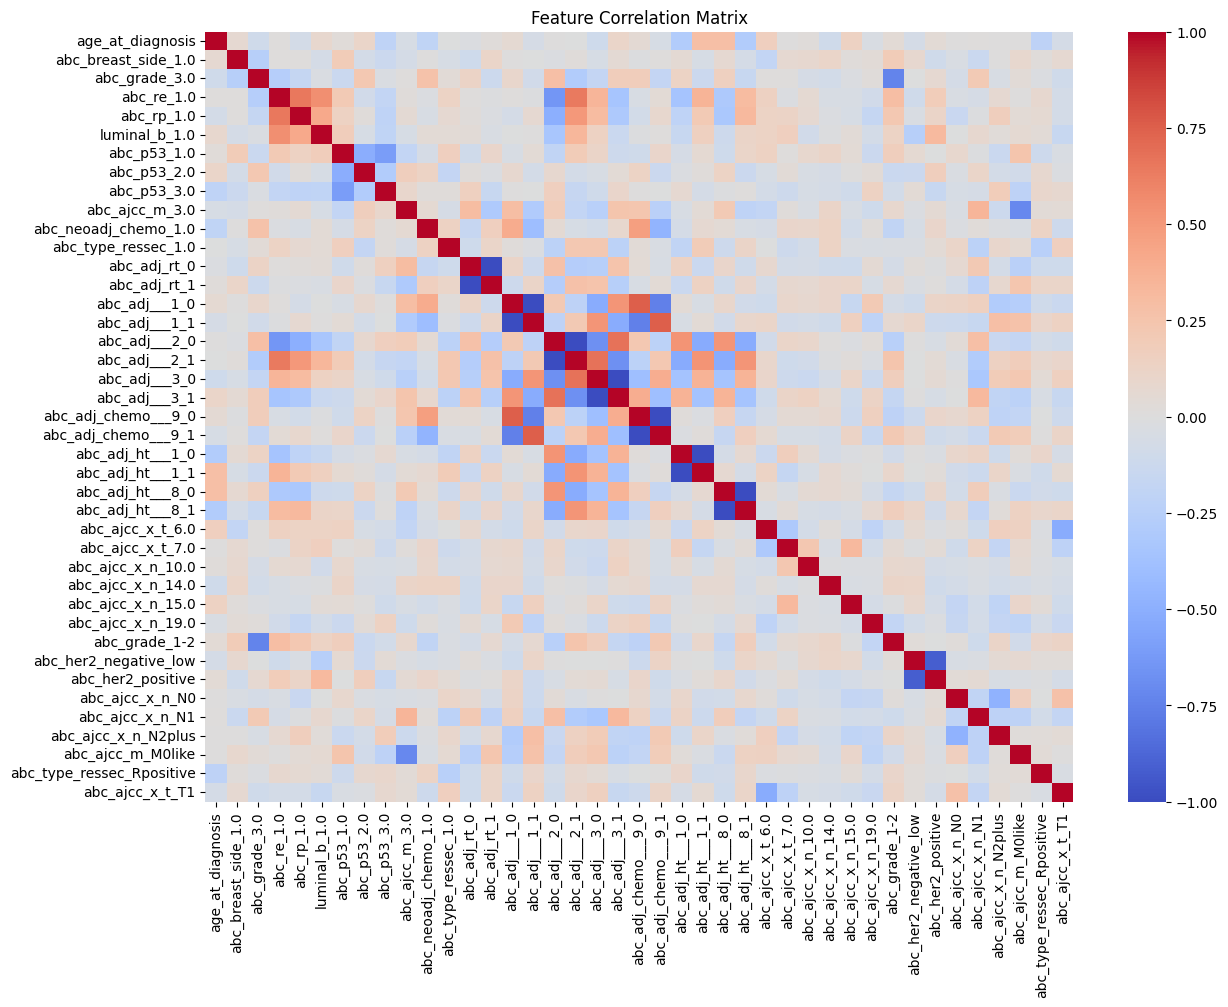

In [21]:
# copy data
df = df_processed.copy()

# Ensure the target is binary and stored as 0/1 integers
target = "Polymetastatic"
df[target] = df[target].astype(int)

# Drop non-numeric columns and datetime-like columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Drop the target from features
features = numeric_df.drop(columns=[target])
# Compute correlation matrix
corr_matrix = features.corr(method='pearson')

# Plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, center=0)
plt.title("Feature Correlation Matrix")
plt.show()


#### Analyze the highly correlated features ####

The correlation matrix identifies potentially redundant features. Domain knowledge and relevance guide which highly correlated features are removed.

In [22]:
# Set the correlation threshold for "high correlation"
threshold = 0.85

# Extract the upper triangle of the correlation matrix, excluding the diagonal,
# to avoid duplicate pairs and self-correlation
high_corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # Mask lower triangle and diagonal
    .stack()  # Stack into a Series with MultiIndex (feature pairs)
    .reset_index()  # Convert MultiIndex to columns for easier filtering and display
)

# Rename columns for clarity
high_corr_pairs.columns = ['Feature1', 'Feature2', 'Correlation']

# Filter pairs where absolute correlation exceeds the threshold
high_corr_pairs = high_corr_pairs[high_corr_pairs['Correlation'].abs() > threshold]

thesis_print(f"Highly correlated feature pairs (>|{threshold}|):")

# Ensure it is a DataFrame (redundant if already DataFrame, but safe)
high_corr_pairs = pd.DataFrame(high_corr_pairs)

# Round correlation values to 2 decimals for readability
high_corr_pairs['Correlation'] = high_corr_pairs['Correlation'].round(2)

# Ensure Correlation column is float type (optional but good for downstream tasks)
high_corr_pairs['Correlation'] = high_corr_pairs['Correlation'].astype(float)

# Display pairs sorted by correlation descending
thesis_display(high_corr_pairs.sort_values(by='Correlation', ascending=False))


Highly correlated feature pairs (>|0.85|):


,Feature1,Feature2,Correlation
792,abc_her2_negative_low,abc_her2_positive,-0.92
414,abc_adj_rt_0,abc_adj_rt_1,-1.00
520,abc_adj___2_0,abc_adj___2_1,-1.00
469,abc_adj___1_0,abc_adj___1_1,-1.00
567,abc_adj___3_0,abc_adj___3_1,-1.00
610,abc_adj_chemo___9_0,abc_adj_chemo___9_1,-1.00
649,abc_adj_ht___1_0,abc_adj_ht___1_1,-1.00
684,abc_adj_ht___8_0,abc_adj_ht___8_1,-1.00


In [23]:
# List of columns identified to be dropped due to high correlation with others
cols_to_drop_corr = [
    'abc_her2_negative_low',
    'abc_adj_rt_0',
    'abc_adj___1_0',
    'abc_adj___2_0',
    'abc_adj___3_0',
    'abc_adj_chemo___9_0',
    'abc_adj_ht___1_0',
    'abc_adj_ht___8_0'
]

# Find columns in the original DataFrame that match the drop list
cols_to_remove = [
    col for col in df.columns
    if col in cols_to_drop_corr
]

# Drop the selected highly correlated columns from the processed DataFrame
df_processed_corr = df_processed.drop(columns=cols_to_remove)

# Print the shape of the DataFrame after dropping columns
thesis_print("Final shape:", df_processed_corr.shape)

Final shape: (149, 36)


## Save data ##

### Saving Model Artifacts for Future Data Processing ###

The `model_artifacts` dictionary contains all essential components for preprocessing and modelling, including:

- The trained `pipeline` for data transformations  
- Lists of numerical columns and columns to keep  
- Templates of cleaned and processed dataframe columns  
- The final list of columns to drop based on correlation analysis  

These artifacts are saved in the file `mcpp-breast-clinical-all-metastatic-data-preprocess-artifacts.pkl`.

They will be used to transform and preprocess new clinical data through the function `preprocess_new_patient_data` in `scripts/utils_clinic.py`, which lies outside the thesis-specific `scripts/OligoPolyThesis/utils_ml_oligopoly.py` module.

In [24]:
model_artifacts = {
    'pipeline': pipeline,
    'numerical_columns': numerical_columns,
    'columns_to_keep': ["record_id", "sample_id", "Oligo_or_Pluri"] + numerical_columns,
    'columns_df_cleaned_template': df_cleaned.columns.to_list(),
    'columns_X_processed_df_el_template': X_processed_df_el.columns.to_list(),
    'groups': list(group_definitions.values()),
    'group_names': list(group_definitions.keys()),
    'columns_to_drop_final': cols_to_drop_corr
}

# Save model artifacts to a file

artifacts_dir = "/mnt/data3/MCPP-Breast/Clinical-Data/artifacts"
os.makedirs(artifacts_dir, exist_ok=True)

artifacts_path = os.path.join(
    artifacts_dir,
    "mcpp-breast-clinical-all-metastatic-data-preprocess-artifacts.pkl"
)

joblib.dump(model_artifacts, artifacts_path)

thesis_print("Saved preprocessing artifacts to:")
thesis_print(artifacts_path)


Saved preprocessing artifacts to:
/mnt/data3/MCPP-Breast/Clinical-Data/artifacts/mcpp-breast-clinical-all-metastatic-data-preprocess-artifacts.pkl


### Create Two Final Preprocessed Datasets ###

At this stage, we create two final versions of the preprocessed clinical dataset:

- **with treatment variables**: retains the current final set of predictors, including treatment-related variables;
- **without treatment variables**: removes all variables whose names contain `"adj"`, including adjuvant and neoadjuvant treatment-related features.

The treatment-free dataset will be used for predictive modelling, while the version with treatment variables may still be useful for exploratory analyses on treatment-outcome associations.

In [27]:
# Create final dataset with treatment variables
df_processed_corr_with_treatment = df_processed_corr.copy()

# Identify treatment-related columns
treatment_cols = [
    col for col in df_processed_corr_with_treatment.columns
    if ("adj" in col.lower()) or ("type_ressec" in col.lower())
]

thesis_print("Treatment-related columns identified:")
thesis_print(treatment_cols)
thesis_print("Number of treatment-related columns:", len(treatment_cols))

# Create final dataset without treatment variables
df_processed_corr_without_treatment = df_processed_corr_with_treatment.drop(
    columns=treatment_cols,
    errors="ignore"
).copy()

thesis_print("\nShape with treatment variables:", df_processed_corr_with_treatment.shape)
thesis_print("Shape without treatment variables:", df_processed_corr_without_treatment.shape)

Treatment-related columns identified:
['abc_neoadj_chemo_1.0', 'abc_type_ressec_1.0', 'abc_adj_rt_1', 'abc_adj___1_1', 'abc_adj___2_1', 'abc_adj___3_1', 'abc_adj_chemo___9_1', 'abc_adj_ht___1_1', 'abc_adj_ht___8_1', 'abc_type_ressec_Rpositive']
Number of treatment-related columns: 10

Shape with treatment variables: (149, 36)
Shape without treatment variables: (149, 26)


### Saving the final preprocessed data ###

In [28]:
# Save final preprocessed dataset WITH treatment variables
df_processed_corr_with_treatment.to_csv(
    path_directory + '20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-with-treatment.csv',
    index=False,
    sep=';'
)

# Save final preprocessed dataset WITHOUT treatment variables
df_processed_corr_without_treatment.to_csv(
    path_directory + '20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-without-treatment.csv',
    index=False,
    sep=';'
)

thesis_print("Saved files:")
thesis_print(path_directory + '20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-with-treatment.csv')
thesis_print(path_directory + '20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-without-treatment.csv')

Saved files:
/mnt/data3/MCPP-Breast/Clinical-Data/20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-with-treatment.csv
/mnt/data3/MCPP-Breast/Clinical-Data/20260401-mcpp-breast-clinical-all-metastatic-data-preprocessing-without-treatment.csv
